# 135 · results tables: decres-rescale-aug10-v1@300
One row per dataset split (src9 `load_splits`), with the boxes / speakers / objects / layouts in it and per-sample IoU@.08 (mean ± std over samples).

Predictions = the run's saved ep300 `outputs_history` (eval splits + train-set eval, model in eval mode). The run trained with `--compile 0`, so these are eager evals (no compile-eval bias).

**kind / group** (the user's mapping, `GROUPS` below; every eval split name is in exactly one group, asserted):
- `easy eval`: cube (cube, cube-rotated) · candle · soap (soap-dispenser, -rotated, -sideways) · vase · glass cup (glass-cup, -broken)
- `hard eval`: cylinder (100g/200g/500g/1000g, all three boxes pooled per weight) · multiple objects (two-cubes, cube-vase)
- `unseen eval`: unseen object · unseen speaker · unseen rotation · unseen laser speckle · unseen position · lid

IoU = `utils.iou08` per sample (pred > .08 vs true > .5); samples with an empty true mask (empty box) have no IoU and are left out of mean/std (`n_iou`).

In [6]:
import sys, glob
from pathlib import Path
import numpy as np, pandas as pd, torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import load_splits, get_splits, CATEGORIES
from score import truth
from utils import THR
RUN, EP = "decres-rescale-aug10-v1", 300
OUT = ROOT / "notebooks/plots/nb135"; OUT.mkdir(parents=True, exist_ok=True)

samples, idxs = load_splits()
metas = list(samples.values())
SPLITS = get_splits()
KEY = {(m["experiment"], m["position_id"], m["speaker"]): i for i, m in enumerate(metas)}

2026_09_27_gastronorm_four_objs: 6155 samples
2026_10_05_green_plastic_four_objs: 5736 samples
2026_10_11_cardboard_four_objs: 7228 samples
split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                

In [2]:
GROUPS = {   # kind -> {group: split names}; the split name is the same in every box ("eval/<box>/<name>")
    "easy eval": {"cube": ["cube", "cube-rotated"], "candle": ["candle"], "soap": ["soap-dispenser", "soap-dispenser-rotated", "soap-dispenser-sideways"], "vase": ["vase"],
                  "glass cup": ["glass-cup", "glass-cup-broken"]},
    "hard eval": {"cylinder": ["cylinder-100g", "cylinder-200g", "cylinder-500g", "cylinder-1000g"], "multiple objects": ["two-cubes", "cube-vase"]},
    "unseen eval": {"unseen object": ["biscoff", "coffee-pot", "tomato-sauce", "portable-charger", "portable-charger-sideways"],
                    "unseen speaker": ["vase-unseen-speaker-unseen", "cube-unseen-speaker-unseen", "vase-unseen-speaker-baseline", "cube-unseen-speaker-baseline"],
                    "unseen rotation": ["soap-dispenser-unseen-angle"],
                    "unseen laser speckle": ["cube-shifted-lasers-1", "cube-shifted-lasers-2", "cube-shifted-lasers-3-backside", "vase-laser-shifted-2", "vase-laser-shifted-3", "vase-laser-shifted-4"],
                    "unseen position": ["unseen-position"],
                    "lid": ["vase-with-lid", "vase-without-lid", "cube-with-lid", "cube-without-lid"]}}
G = {s: (k, g) for k, gs in GROUPS.items() for g, ss in gs.items() for s in ss}   # split name -> (kind, group)
GORDER = [g for gs in GROUPS.values() for g in gs]
assert len(G) == sum(len(ss) for gs in GROUPS.values() for ss in gs.values()), "a split is in two groups"
names = {n.split("/")[-1] for n in idxs if n != "train"}
assert names <= set(G), f"unassigned: {names - set(G)}"
print("unused group entries:", set(G) - names)
kind = lambda n: "train" if n == "train" else G[n.split("/")[-1]][0]
group = lambda n: "train" if n == "train" else G[n.split("/")[-1]][1]

PRED = {}   # (split, meta index) -> mask (64,64); train and eval kept separate
for f in sorted(glob.glob(str(ROOT / f"runs/{RUN}/outputs_history/eval/*/*/ep{EP:04d}-*.pt"))) + sorted(glob.glob(str(ROOT / f"runs/{RUN}/outputs_history/train/ep{EP:04d}-*.pt"))):
    d = torch.load(f, weights_only=False, map_location="cpu")
    split = "train" if "/train/" in f else "eval/" + "/".join(Path(f).parts[-3:-1])
    for p, e, pos, spk in zip(d["mask_pred"].float().numpy(), d["info"]["experiment"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()):
        PRED[split, KEY[e, pos, spk]] = p
print(len(PRED), "saved predictions")

unused group entries: set()
15891 saved predictions


In [3]:
rows = []
for name, ids in idxs.items():
    for i in ids:
        m = metas[i]
        p = PRED.get((name, i))
        sid = int(m["sample_id"]) if str(m["sample_id"]).isdigit() else -1
        y = truth(m["experiment"], sid, m["position_id"], m["speaker"], 64, 64) > 0.5
        b = p > THR if p is not None else None
        iou = np.nan if p is None or not y.any() else (b & y).sum() / (b | y).sum()
        rows.append(dict(sample_id=m["sample_id"], position_id=m["position_id"], split=name, kind=kind(name), group=group(name), box=m["box"], speaker=m["speaker"],
                         object="+".join(sorted(m["objects"])) or "empty", layout=m["layout"], has_pred=p is not None, iou=iou))
df = pd.DataFrame(rows)
df.to_csv(OUT / "per_sample.csv", index=False)
print(len(df), "samples ·", (~df.has_pred).sum(), "without a saved prediction")
df.groupby("split").has_pred.mean().loc[lambda s: s < 1]

15891 samples · 0 without a saved prediction


Series([], Name: has_pred, dtype: float64)

In [4]:
j = lambda s: ", ".join(map(str, sorted(set(s))))
name = lambda s: s.split("/")[-1]   # "eval/cardboard/cube" -> "cube"
t = df.groupby("split").agg(kind=("kind", "first"), group=("group", "first"), box=("box", j), speakers=("speaker", j), objects=("object", j),
                            n_samples=("iou", "size"), n_iou=("iou", "count"), iou_mean=("iou", "mean"), iou_std=("iou", "std")).reset_index()
t["split"] = t.split.map(name)
import re
nat = lambda s: tuple(int(x) if x.isdigit() else x for x in re.split(r"(\d+)", s))   # natural sort: 100g < 200g < 1000g
K = ["train", "easy eval", "hard eval", "unseen eval"]
GO = ["train"] + GORDER
t = t.sort_values(["kind", "group", "split", "box"], key=lambda s: s.map(K.index) if s.name == "kind" else s.map(GO.index) if s.name == "group" else s.map(nat) if s.name == "split" else s).reset_index(drop=True)
t = t[["group"] + [x for x in t.columns if x != "group"]]
t["iou"] = t.iou_mean.map("{:.3f}".format) + " ± " + t.iou_std.map("{:.3f}".format)
t.to_csv(OUT / "splits.csv", index=False)
pd.set_option("display.max_rows", 300, "display.max_colwidth", 80)
t.drop(columns=["iou_mean", "iou_std"])

,group,split,kind,box,speakers,objects,n_samples,n_iou,iou
0,train,train,train,"cardboard, gastronorm, green-plastic","1, 3, 5, 7","candle, cylinder-1000g, cylinder-100g, cylinder-200g, cylinder-500g, empty, ...",11219,11050,0.890 ± 0.126
1,cube,cube,easy eval,cardboard,"1, 3, 5, 7",red-cube,221,221,0.515 ± 0.251
2,cube,cube,easy eval,gastronorm,"1, 3, 7",red-cube,147,147,0.590 ± 0.213
3,cube,cube,easy eval,green-plastic,"1, 3, 5, 7",red-cube,200,200,0.711 ± 0.121
4,cube,cube-rotated,easy eval,cardboard,"1, 3, 5, 7",red-cube,20,20,0.509 ± 0.205
5,candle,candle,easy eval,cardboard,"1, 3, 5, 7",candle,230,230,0.848 ± 0.063
6,candle,candle,easy eval,gastronorm,"1, 3, 7",candle,156,156,0.851 ± 0.061
7,candle,candle,easy eval,green-plastic,"1, 3, 5, 7",candle,204,204,0.815 ± 0.096
8,soap,soap-dispenser,easy eval,cardboard,"1, 3, 5, 7",soap dispenser,215,215,0.712 ± 0.141
9,soap,soap-dispenser,easy eval,gastronorm,"1, 3, 7",soap dispenser,146,146,0.795 ± 0.105


## What trained
Train split broken down by box × layout × object (speakers listed), IoU on the saved ep300 train-set eval.

Check against the split definition: the train layouts must be exactly the layouts of the splits with `eval_frac < 1` (held-out positions of those layouts, plus the empty boxes at `eval_frac = 0`); fully held-out splits (`eval_frac = 1`) contribute nothing unless they share a layout with a trained split.

In [5]:
tr = df[df.split == "train"]
a = tr.groupby(["box", "layout", "object"]).agg(speakers=("speaker", j), n_samples=("iou", "size"), n_iou=("iou", "count"), iou_mean=("iou", "mean"), iou_std=("iou", "std"))
a["iou"] = a.iou_mean.map("{:.3f}".format) + " ± " + a.iou_std.map("{:.3f}".format)
BOXNAME = {"2026_09_27_gastronorm_four_objs": "gastronorm", "2026_10_05_green_plastic_four_objs": "green-plastic", "2026_10_11_cardboard_four_objs": "cardboard"}
want = {(BOXNAME[s["experiment"]], l) for s in SPLITS.values() if s["eval_frac"] < 1 for l in s["layouts"]}
have = set(zip(tr.box, tr.layout))
print("train layouts == layouts of eval_frac<1 splits:", have == want, "· missing:", sorted(want - have), "· extra:", sorted(have - want))
print("train samples:", len(tr), "== len(idxs['train']):", len(idxs["train"]))
a.drop(columns=["iou_mean", "iou_std"])

train layouts == layouts of eval_frac<1 splits: False · missing: [('cardboard', 'cylinder-500g-grid-2.')] · extra: []
train samples: 11219 == len(idxs['train']): 11219


speakers  \
box           layout                   object                            
cardboard     candle-grid-1            candle               1, 3, 5, 7   
              candle-grid-2            candle               1, 3, 5, 7   
              candle-grid-3            candle               1, 3, 5, 7   
              cube-different-rotations red-cube             1, 3, 5, 7   
              cube-grid-1              red-cube             1, 3, 5, 7   
              cube-grid-2              red-cube             1, 3, 5, 7   
              cube-random-pos2         red-cube             1, 3, 5, 7   
              cube-random_poses        red-cube             1, 3, 5, 7   
              cube-vase                red-cube+vase        1, 3, 5, 7   
              cylinder-1000g           cylinder-1000g       1, 3, 5, 7   
              cylinder-1000g-grid-1    cylinder-1000g       1, 3, 5, 7   
              cylinder-100g-grid-1     cylinder-100g        1, 3, 5, 7   
              cylinder-200g-grid-1     cylinder-200g        1, 3, 5, 7   
              cylinder-200g-grid-2     cylinder-200g        1, 3, 5, 7   
              cylinder-500g-grid-1     cylinder-500g        1, 3, 5, 7   
              cylinder-500g-grid-2     cylinder-500g        1, 3, 5, 7   
              empty-box-3              empty                1, 3, 5, 7   
              empty-box-4              empty                1, 3, 5, 7   
              empty-box-5              empty                1, 3, 5, 7   
              empty-box-6              empty                1, 3, 5, 7   
              empty-box-grid-1         empty                1, 3, 5, 7   
              empty-box-grid-2         empty                1, 3, 5, 7   
              glass-cup                glass-cup            1, 3, 5, 7   
              glass-cup-broken         glass-cup            1, 3, 5, 7   
              soap-dispenser-grid-1    soap dispenser       1, 3, 5, 7   
              soap-dispenser-grid-2    soap dispenser       1, 3, 5, 7   
              soap-dispenser-grid-3    soap dispenser       1, 3, 5, 7   
              soap-dispenser-rotated   soap dispenser       1, 3, 5, 7   
              soap-dispenser-rotated-2 soap dispenser       1, 3, 5, 7   
              soap-dispenser-sideways  soap dispenser       1, 3, 5, 7   
              two-cubes                green-cube+red-cube  1, 3, 5, 7   
              vase-grid-1              vase                 1, 3, 5, 7   
              vase-grid-2              vase                 1, 3, 5, 7   
              vase-grid-3              vase                 1, 3, 5, 7   
gastronorm    candle                   candle                  1, 3, 7   
              cube-vase                red-cube+vase           1, 3, 7   
              empty-box-1              empty                   1, 3, 7   
              empty-box-2              empty                   1, 3, 7   
              empty-box-3              empty                   1, 3, 7   
              empty-box-4              empty                   1, 3, 7   
              red-cube-grid1           red-cube                1, 3, 7   
              red-cube-grid2           red-cube                1, 3, 7   
              red-cube-grid3_test      red-cube                1, 3, 7   
              soap-dispenser-grid-1    soap dispenser          1, 3, 7   
              soap-dispenser-grid-2    soap dispenser          1, 3, 7   
              soap-dispenser-grid-3    soap dispenser          1, 3, 7   
              two-cubes-grid-1         green-cube+red-cube     1, 3, 7   
              two-cubes-grid-2         green-cube+red-cube     1, 3, 7   
              vase-grid-1              vase                    1, 3, 7   
green-plastic candle-grid-1            candle               1, 3, 5, 7   
              candle-grid-2            candle               1, 3, 5, 7   
              candle-grid-3            candle               1, 3, 5, 7   
              cube-box-grid-1          red-cube             1, 3, 

### cardboard cylinder-100g
It does train (layout `cylinder-100g-grid-1`, the only layout of `cardboard/cylinder-100g`, eval_frac .2). The masks are not broken: the object is a ~38 px wide disk in the 1287×907 crop, which is 3–6 px after the 64×64 BOX downsample (candle ≈ 156 px). Train IoU is only .27 and eval IoU is 0 on all 36 samples: the model can't resolve, let alone generalize, an object that small.

n  gt_px64  gt_px64_min    iou
object         part                                   
candle         eval   230  147.413          124  0.848
               train  917  148.068          122  0.923
cylinder-1000g eval    28   25.286           20  0.213
               train  107   24.168           10  0.844
cylinder-100g  eval    36    4.333            3  0.000
               train  135    4.867            3  0.271
cylinder-200g  eval    40    7.900            6  0.020
               train  153    8.131            6  0.497
cylinder-500g  eval    40   14.400           12  0.051
               train  159   16.057           12  0.758

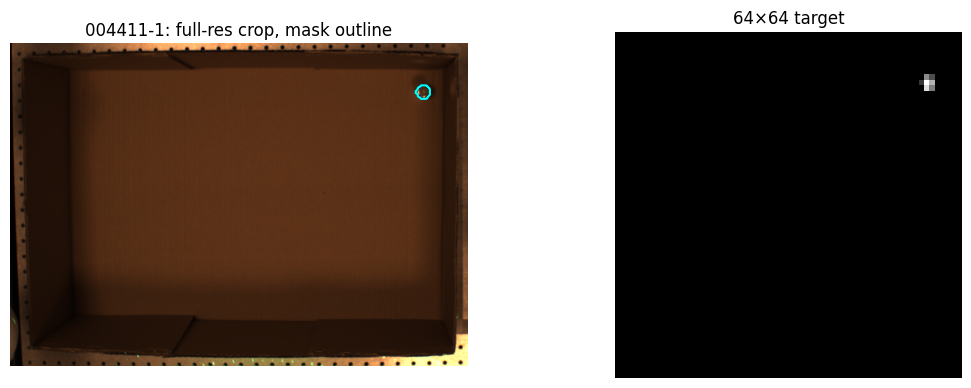

In [6]:
from PIL import Image
import matplotlib.pyplot as plt
EXP = {v: k for k, v in BOXNAME.items()}
sid = lambda x: int(x) if str(x).isdigit() else -1
area = lambda r: (truth(EXP[r.box], sid(r.sample_id), r.position_id, r.speaker, 64, 64) > .5).sum()
c = df[(df.box == "cardboard") & df.object.isin(["cylinder-100g", "cylinder-200g", "cylinder-500g", "cylinder-1000g", "candle"])].copy()
c["gt_px64"] = [area(r) for r in c.itertuples()]
c["part"] = np.where(c.split == "train", "train", "eval")
display(c.groupby(["object", "part"]).agg(n=("iou", "size"), gt_px64=("gt_px64", "mean"), gt_px64_min=("gt_px64", "min"), iou=("iou", "mean")).round(3))
d = next(k for k, m in samples.items() if m["layout"] == "cylinder-100g-grid-1")
im, mk = np.asarray(Image.open(d / "image/02_cropped_overhead.png").convert("RGB")), np.asarray(Image.open(d / "image/03_smask.png").convert("L")) > 127
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); ax[0].imshow(im); ax[0].contour(mk, colors="cyan"); ax[0].set_title(f"{d.name}: full-res crop, mask outline")
ax[1].imshow(truth(EXP["cardboard"], sid(samples[d]["sample_id"]), samples[d]["position_id"], samples[d]["speaker"], 64, 64), cmap="gray"); ax[1].set_title("64×64 target")
for x in ax: x.axis("off")

## Paired table: train vs eval per split
Wide format: one row per split name, pooling the samples of every box that has it (`box` = the boxes pooled), e.g. `cylinder-100g` = cardboard (held-out positions of a trained layout) + gastronorm + green-plastic (fully held out). `group` is the outer index level; kind/group from `GROUPS`.

**Matching rule.** For each box's eval split S (its (layout, object) pairs, speakers K), the matched train samples are the train samples with the same box, (layout, object) in S's pairs and speaker in K. If none of them has a speaker in K (the speaker-4 `*-unseen-speaker-unseen` splits), the speaker filter is dropped. `n_train` / `train_iou` = the union of those per-box matches, `train_box` = the boxes that contributed train samples (can be fewer than `box`). Blank train columns = no box's split has a trained (layout, object), i.e. the layouts are fully held out (e.g. plastic `cube-unseen-speaker-baseline` is the separate `cube-5-speakers` capture, which never trains).

Only `eval_iou` is coloured, by kind: easy eval = green, hard eval = amber, unseen eval = red. Second table: the same per group, pooled over all its eval samples (and the union of its matched train samples).

**Synthetic baselines (`*`, `synthetic = yes`; not splits defined in `dataset.py`, so outside the every-split-assigned assert).** Analogous to the speaker baselines: held-out positions, but the tested property is a trained one.
- `unseen-rotation-baseline*` (above `soap-dispenser-unseen-angle`): the `eval/cardboard/soap-dispenser-rotated` samples from layouts `soap-dispenser-rotated` / `-rotated-2` (sideways excluded), i.e. held-out positions at trained angles. Asserted: none is in `UNSEEN_ANGLE`, the +30..+60° wedge. Train columns = the unseen-angle split's reference (386).
- `unseen-position-baseline*` (above `unseen-position`): per box, the `eval/<box>/vase` samples from the layouts unseen-position uses (green-plastic: grid-2/3 only), i.e. held-out positions outside the region. Asserted: zero vase footprint in `REGION`. Train columns = the unseen-position reference (1324).
- Group table: the real group rows pool only dataset splits; each baseline is a separate `<group> baseline*` row directly above its group.

In [7]:
M = {}   # eval split -> index of its matched train samples
for s, g in df[df.split != "train"].groupby("split", sort=False):
    pairs = set(zip(g.layout, g.object))
    m = tr[(tr.box == g.box.iloc[0]) & np.array([p in pairs for p in zip(tr.layout, tr.object)])]
    M[s] = m[m.speaker.isin(g.speaker)].index if m.speaker.isin(g.speaker).any() else m.index
ev = df[df.split != "train"].assign(name=lambda d: d.split.map(name))
ms = lambda g: f"{g.iou.mean():.3f} ± {g.iou.std():.3f}"
def row(g, ref=None, **kw):   # ref = eval splits whose matched train samples form the train columns (default: g's own splits)
    t_ = df.loc[sorted(set().union(*[M[s] for s in (g.split.unique() if ref is None else ref)]))]
    return dict(kw, kind=g.kind.iloc[0], box=j(g.box), train_box=j(t_.box) if len(t_) else "", speakers=j(g.speaker), objects=j(g.object),
                n_train=len(t_) if len(t_) else "", train_iou=ms(t_) if len(t_) else "", n_eval=len(g), eval_iou=ms(g))
COL = {"easy eval": "#dcf0dc", "hard eval": "#fbe8c8", "unseen eval": "#f8d7d7"}
def style(p, group_lines=True):   # eval_iou coloured by kind; 3px line between kinds, 2px between groups (first row of each section)
    k, g = p.kind.values, p.index.get_level_values(0)
    top = ["border-top: 3px solid #222" if i and k[i] != k[i - 1] else "border-top: 2px solid #222" if i and group_lines and g[i] != g[i - 1] else "" for i in range(len(p))]
    rows = lambda d: pd.DataFrame([[t] * d.shape[1] for t in top], index=d.index, columns=d.columns)
    return (p.style.apply(rows, axis=None).apply_index(lambda s: top, axis=0, level=list(range(p.index.nlevels)))
            .apply(lambda c: [f"background-color: {COL[x]}; color: black; {t}" for x, t in zip(k, top)], subset=["eval_iou"]))
# synthetic baselines (not dataset splits): held-out positions where the tested property is a trained one
from dataset import UNSEEN_ANGLE, region_overlap
rb = ev[(ev.split == "eval/cardboard/soap-dispenser-rotated") & ev.layout.isin(["soap-dispenser-rotated", "soap-dispenser-rotated-2"])]
assert not rb.position_id.isin(UNSEEN_ANGLE).any()   # all outside the +30..+60 wedge
up = ev[ev.name == "unseen-position"]
pb = pd.concat([ev[(ev.split == f"eval/{b}/vase") & ev.layout.isin(u.layout)] for b, u in up.groupby(up.split.str.split("/").str[1])])
assert all(region_overlap(EXP[r.box]).get(r.position_id, 0.0) == 0 for r in pb.itertuples())   # zero vase footprint in REGION
SYN = [("unseen rotation", "unseen-rotation-baseline", rb, ["eval/cardboard/soap-dispenser-unseen-angle"], "soap-dispenser-unseen-angle"),
       ("unseen position", "unseen-position-baseline", pb, list(up.split.unique()), "unseen-position")]
p = pd.DataFrame([dict(row(g, group=g.group.iloc[0], split=n), synthetic="", base=n) for n, g in ev.groupby("name")] +
                 [dict(row(g.assign(kind="unseen eval"), ref, group=gr, split=n + "*"), synthetic="yes", base=b) for gr, n, g, ref, b in SYN])
p = p.sort_values(["group", "base", "synthetic"], key=lambda s: s.map(GORDER.index) if s.name == "group" else s.map(nat) if s.name == "base" else s != "yes")
p = p.drop(columns="base").set_index(["group", "split"])
p.to_csv(OUT / "splits_paired.csv")
style(p)

In [8]:
# real groups pool only dataset splits; each synthetic baseline is its own group row ("<group> baseline*"), directly above its group
q = pd.DataFrame([dict(row(g, group=n), synthetic="", order=GORDER.index(n)) for n, g in ev.groupby("group")] +
                 [dict(row(g.assign(kind="unseen eval"), ref, group=gr + " baseline*"), synthetic="yes", order=GORDER.index(gr) - .5) for gr, n, g, ref, b in SYN])
q = q.sort_values("order").drop(columns="order").set_index("group")
q.to_csv(OUT / "groups.csv")
style(q, group_lines=False)   # one row per group: lines between kinds only

,kind,box,train_box,speakers,objects,n_train,train_iou,n_eval,eval_iou,synthetic
group,,,,,,,,,,
cube,easy eval,"cardboard, gastronorm, green-plastic","cardboard, gastronorm, green-plastic","1, 3, 5, 7",red-cube,2362,0.909 ± 0.077,588,0.600 ± 0.220,
candle,easy eval,"cardboard, gastronorm, green-plastic","cardboard, gastronorm, green-plastic","1, 3, 5, 7",candle,2346,0.925 ± 0.024,590,0.837 ± 0.078,
soap,easy eval,"cardboard, gastronorm, green-plastic","cardboard, gastronorm, green-plastic","1, 3, 5, 7",soap dispenser,2807,0.903 ± 0.069,741,0.728 ± 0.153,
vase,easy eval,"cardboard, gastronorm, green-plastic","cardboard, gastronorm, green-plastic","1, 3, 5, 7",vase,1692,0.915 ± 0.027,438,0.818 ± 0.105,
glass cup,easy eval,cardboard,cardboard,"1, 3, 5, 7",glass-cup,96,0.838 ± 0.038,24,0.453 ± 0.175,
cylinder,hard eval,"cardboard, gastronorm, green-plastic",cardboard,"1, 3, 5, 7","cylinder-1000g, cylinder-100g, cylinder-200g, cylinder-500g",554,0.584 ± 0.366,331,0.126 ± 0.140,
multiple objects,hard eval,"cardboard, gastronorm, green-plastic","cardboard, gastronorm, green-plastic","1, 3, 5, 7","green-cube+red-cube, red-cube+vase",1193,0.863 ± 0.101,310,0.383 ± 0.164,
unseen object,unseen eval,"cardboard, gastronorm, green-plastic",,"1, 3, 5, 7","biscoff, coffee pot, portable-charger, tomato sauce",,,586,0.564 ± 0.162,
unseen speaker,unseen eval,"cardboard, gastronorm, green-plastic",gastronorm,"1, 3, 4, 5, 7","red-cube, vase",589,0.886 ± 0.091,389,0.643 ± 0.213,
